# Retail Sales Performance Analysis (Python)

**Goal:** clean the Superstore retail dataset, validate it, and answer business questions about growth, profitability, discounts, regions and returns.

**Data:** Sample Superstore (Tableau sample data, public). Three tables: Orders, People (regional managers), Returns. US retail orders, 2015-2018.

**Pipeline:** raw CSVs -> cleaning -> validation checks -> analysis -> `data/processed/orders_clean.csv` (used by Excel cross-checks and Power BI).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.options.display.float_format = '{:,.2f}'.format
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
ROOT = Path('..')
IMG = ROOT / 'images'; IMG.mkdir(exist_ok=True)
BLUE, ORANGE, RED, GREY = '#1F4E79', '#E07B39', '#C0392B', '#8C8C8C'

## 1. Load raw data

In [2]:
orders  = pd.read_csv(ROOT/'data/raw/orders.csv', dtype={'Postal Code': 'string'})
people  = pd.read_csv(ROOT/'data/raw/people.csv')
returns = pd.read_csv(ROOT/'data/raw/returns.csv')
print('orders :', orders.shape, '| people:', people.shape, '| returns:', returns.shape)
orders.head(3)

orders : (9994, 21) | people: (4, 2) | returns: (800, 2)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87


In [3]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   string 
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

## 2. Cleaning

Each step is logged so the changes are traceable. Rule used throughout: change data only when there is a clear reason, and record it.

In [4]:
log = []
raw_rows = len(orders)

# 2.1 Data types: dates are text in the raw file (month/day/year)
orders['Order Date'] = pd.to_datetime(orders['Order Date'], format='%m/%d/%Y')
orders['Ship Date']  = pd.to_datetime(orders['Ship Date'],  format='%m/%d/%Y')
log.append(('Converted Order Date / Ship Date from text to dates', 'all rows'))

# 2.2 Whitespace / case check on text columns
text_cols = orders.select_dtypes(include=['object', 'string']).columns
changed = 0
for c in text_cols:
    cleaned = orders[c].str.strip()
    changed += int((cleaned != orders[c]).sum())
    orders[c] = cleaned
log.append(('Trimmed leading/trailing spaces in text columns', f'{changed} cells changed'))

# 2.3 Duplicates: identical on every column except Row ID
key_cols = [c for c in orders.columns if c != 'Row ID']
dup_mask = orders.duplicated(subset=key_cols, keep='first')
print('Duplicate order lines found:'); display(orders[orders.duplicated(subset=key_cols, keep=False)][['Row ID','Order ID','Product Name','Sales','Quantity']])
removed_sales = orders.loc[dup_mask, 'Sales'].sum()
orders = orders[~dup_mask].copy()
log.append(('Removed exact duplicate order lines (all columns equal except Row ID)', f'{int(dup_mask.sum())} row, sales {removed_sales:,.2f}'))

Duplicate order lines found:


,Row ID,Order ID,Product Name,Sales,Quantity
3405,3406,US-2015-150119,Global Leather Highback Executive Chair with P...,281.37,2
3406,3407,US-2015-150119,Global Leather Highback Executive Chair with P...,281.37,2


In [5]:
# 2.4 Missing values
print(orders.isna().sum()[orders.isna().sum() > 0])
print(orders.loc[orders['Postal Code'].isna(), ['City', 'State']].drop_duplicates())

Postal Code    11
dtype: int64
            City    State
2234  Burlington  Vermont


In [6]:
# All 11 missing postal codes are Burlington, Vermont. The ZIP for Burlington VT is 05401 (public reference).
# Kept as text so the leading zero is not lost.
n_missing = int(orders['Postal Code'].isna().sum())
orders.loc[orders['Postal Code'].isna() & (orders['City'] == 'Burlington') & (orders['State'] == 'Vermont'), 'Postal Code'] = '05401'
assert orders['Postal Code'].isna().sum() == 0
log.append(('Filled missing Postal Code for Burlington, Vermont with 05401', f'{n_missing} rows'))

# 2.5 Returns table: the raw file repeats order IDs
n_ret_raw = len(returns)
returns = returns[['Order ID']].drop_duplicates().assign(Returned='Yes')
log.append(('Returns table: removed repeated Order IDs', f'{n_ret_raw} -> {len(returns)} unique returned orders'))

pd.DataFrame(log, columns=['Cleaning step', 'Impact'])

,Cleaning step,Impact
0,Converted Order Date / Ship Date from text to ...,all rows
1,Trimmed leading/trailing spaces in text columns,0 cells changed
2,Removed exact duplicate order lines (all colum...,"1 row, sales 281.37"
3,"Filled missing Postal Code for Burlington, Ver...",11 rows
4,Returns table: removed repeated Order IDs,800 -> 296 unique returned orders


## 3. Validation checks

In [7]:
checks = {
 'No missing values in any column':            orders.isna().sum().sum() == 0,
 'Ship Date is never before Order Date':       (orders['Ship Date'] >= orders['Order Date']).all(),
 'Sales > 0 on every line':                    (orders['Sales'] > 0).all(),
 'Quantity >= 1 on every line':                (orders['Quantity'] >= 1).all(),
 'Discount between 0 and 1':                   orders['Discount'].between(0, 1).all(),
 'Each State belongs to exactly one Region':   orders.groupby('State')['Region'].nunique().max() == 1,
 'Every Product ID has one Category':          orders.groupby('Product ID')['Category'].nunique().max() == 1,
 'Every returned Order ID exists in Orders':   returns['Order ID'].isin(orders['Order ID']).all(),
 'Every Region has a regional manager':        set(orders['Region']) <= set(people['Region']),
}
pd.Series(checks, name='Passed')

No missing values in any column             True
Ship Date is never before Order Date        True
Sales > 0 on every line                     True
Quantity >= 1 on every line                 True
Discount between 0 and 1                    True
Each State belongs to exactly one Region    True
Every Product ID has one Category           True
Every returned Order ID exists in Orders    True
Every Region has a regional manager         True
Name: Passed, dtype: bool

In [8]:
assert all(checks.values()), 'A validation check failed'
print('Rows after cleaning:', len(orders), '| raw rows:', raw_rows)

Rows after cleaning: 9993 | raw rows: 9994


## 4. Feature engineering

New columns used in the analysis (the same ones are built with formulas in the Excel workbook):
`Order Year`, `Order Month`, `Year-Month`, `Profit Margin`, `Discount Band`, `Returned`, `Regional Manager`, `Ship Days`.

In [9]:
df = orders.copy()
df['Order Year']  = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Year-Month']  = df['Order Date'].dt.to_period('M').astype(str)
df['Profit Margin'] = df['Profit'] / df['Sales']
df['Ship Days']   = (df['Ship Date'] - df['Order Date']).dt.days

# Same band edges as the Excel formula: 0%, up to 10%, up to 20%, up to 30%, up to 50%, above 50%
bins   = [-0.001, 0.0, 0.10, 0.20, 0.30, 0.50, 1.0]
labels = ['0%', '0-10%', '10-20%', '20-30%', '30-50%', '50%+']
df['Discount Band'] = pd.cut(df['Discount'], bins=bins, labels=labels)

df = df.merge(returns, on='Order ID', how='left')
df['Returned'] = df['Returned'].fillna('No')
df = df.merge(people.rename(columns={'Person': 'Regional Manager'}), on='Region', how='left')
df.shape

(9993, 29)

## 5. Headline KPIs

In [10]:
total_sales  = df['Sales'].sum()
total_profit = df['Profit'].sum()
n_orders     = df['Order ID'].nunique()
kpi = pd.Series({
    'Total Sales':          total_sales,
    'Total Profit':         total_profit,
    'Profit Margin %':      total_profit / total_sales * 100,
    'Orders':               n_orders,
    'Average Order Value':  total_sales / n_orders,
    'Customers':            df['Customer ID'].nunique(),
    'Units Sold':           df['Quantity'].sum(),
})
kpi

Total Sales           2,296,919.49
Total Profit            286,409.08
Profit Margin %              12.47
Orders                    5,009.00
Average Order Value         458.56
Customers                   793.00
Units Sold               37,871.00
dtype: float64

## 6. Growth and seasonality

In [11]:
yearly = df.groupby('Order Year').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique'))
yearly['Margin %'] = yearly['Profit'] / yearly['Sales'] * 100
yearly['Sales YoY %'] = yearly['Sales'].pct_change() * 100
yearly

,Sales,Profit,Orders,Margin %,Sales YoY %
Order Year,,,,,
2015,"483,966.13","49,556.03",969,10.24,NaN
2016,"470,532.51","61,618.60",1038,13.10,-2.78
2017,"609,205.60","81,795.17",1315,13.43,29.47
2018,"733,215.26","93,439.27",1687,12.74,20.36


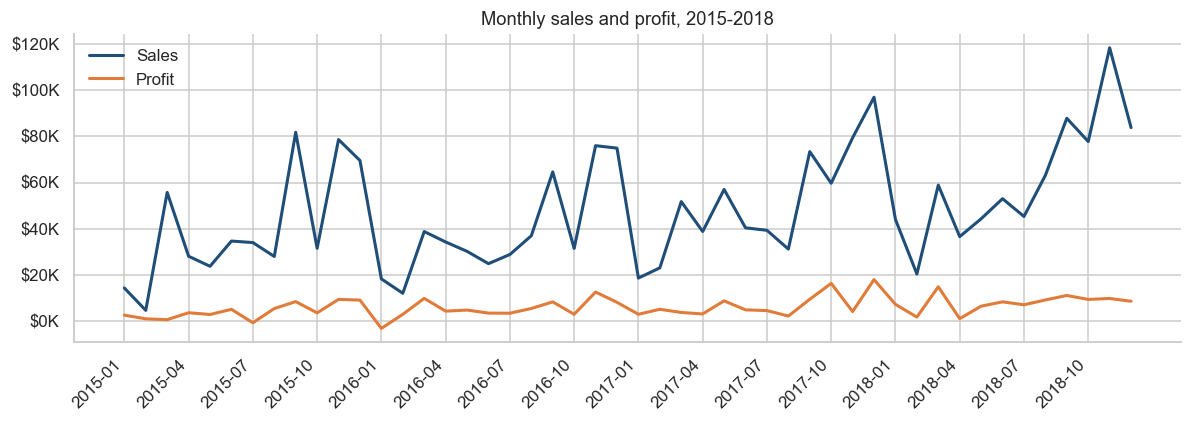

In [12]:
monthly = df.groupby('Year-Month').agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
monthly['MoM %'] = monthly['Sales'].pct_change() * 100

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly['Sales'], color=BLUE, lw=2, label='Sales')
ax.plot(monthly.index, monthly['Profit'], color=ORANGE, lw=2, label='Profit')
ax.set_xticks(range(0, len(monthly), 3)); ax.set_xticklabels(monthly.index[::3], rotation=45, ha='right')
ax.yaxis.set_major_formatter(lambda x, p: f'${x/1000:,.0f}K')
ax.set_title('Monthly sales and profit, 2015-2018'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(IMG/'01_monthly_trend.png'); plt.show()

Sep + Nov + Dec = 42.9% of all sales; Jan + Feb = 6.7%


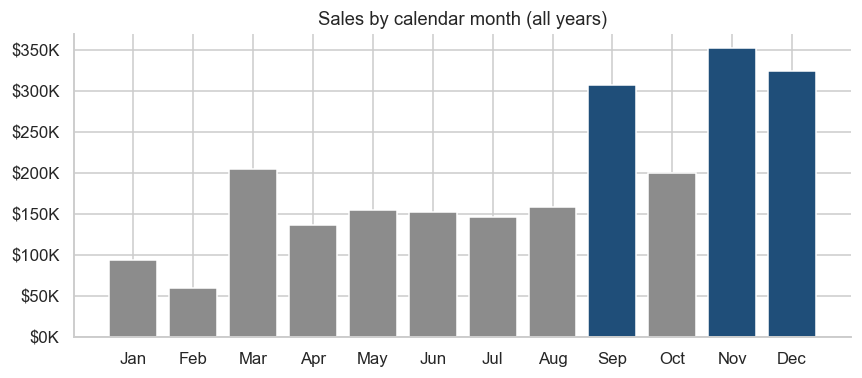

In [13]:
season = df.groupby('Order Month')['Sales'].sum()
share = season / season.sum() * 100
print(f"Sep + Nov + Dec = {share[[9,11,12]].sum():.1f}% of all sales; Jan + Feb = {share[[1,2]].sum():.1f}%")

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE if m in (9, 11, 12) else GREY for m in season.index]
ax.bar(season.index, season.values, color=colors)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.yaxis.set_major_formatter(lambda x, p: f'${x/1000:,.0f}K')
ax.set_title('Sales by calendar month (all years)')
plt.tight_layout(); plt.savefig(IMG/'02_seasonality.png'); plt.show()

## 7. Category and sub-category profitability

In [14]:
cat = df.groupby('Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
cat['Margin %'] = cat['Profit'] / cat['Sales'] * 100
cat['Share of Sales %'] = cat['Sales'] / cat['Sales'].sum() * 100
cat['Share of Profit %'] = cat['Profit'] / cat['Profit'].sum() * 100
cat

,Sales,Profit,Margin %,Share of Sales %,Share of Profit %
Category,,,,,
Furniture,"741,718.42","18,463.33",2.49,32.29,6.45
Office Supplies,"719,047.03","122,490.80",17.04,31.30,42.77
Technology,"836,154.03","145,454.95",17.40,36.40,50.79


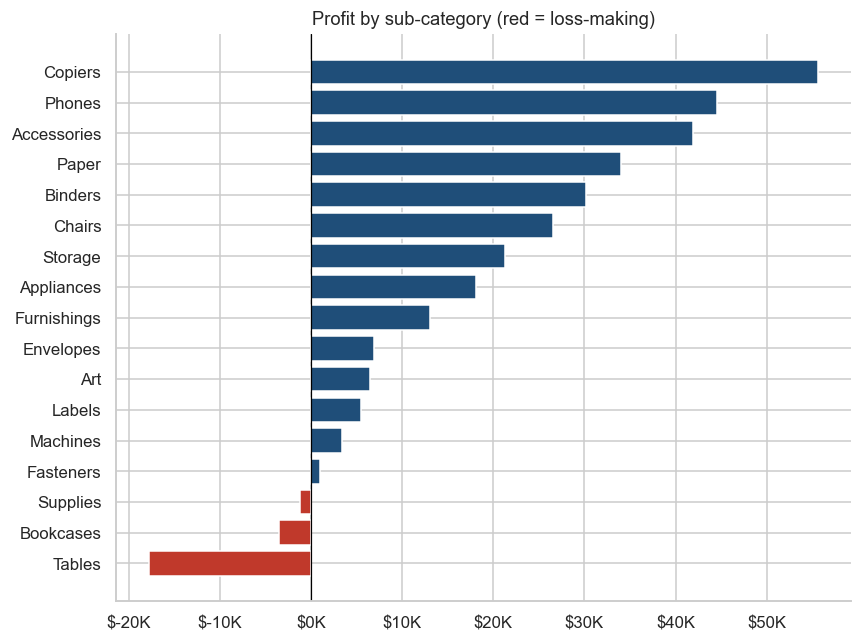

,Sales,Profit,AvgDiscount,Margin %
Sub-Category,,,,
Tables,"206,965.53","-17,725.48",0.26,-8.56
Bookcases,"114,880.00","-3,472.56",0.21,-3.02
Supplies,"46,673.54","-1,189.10",0.08,-2.55
Machines,"189,238.63","3,384.76",0.31,1.79
Chairs,"328,167.73","26,602.23",0.17,8.11
Storage,"223,843.61","21,278.83",0.07,9.51
Phones,"330,007.05","44,515.73",0.15,13.49
Furnishings,"91,705.16","13,059.14",0.14,14.24
Binders,"203,412.73","30,221.76",0.37,14.86


In [15]:
sub = df.groupby('Sub-Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), AvgDiscount=('Discount','mean'))
sub['Margin %'] = sub['Profit'] / sub['Sales'] * 100
sub = sub.sort_values('Profit')

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(sub.index, sub['Profit'], color=[RED if v < 0 else BLUE for v in sub['Profit']])
ax.xaxis.set_major_formatter(lambda x, p: f'${x/1000:,.0f}K')
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Profit by sub-category (red = loss-making)')
plt.tight_layout(); plt.savefig(IMG/'03_subcategory_profit.png'); plt.show()
sub.sort_values('Margin %')

## 8. Discounts and profit

In [16]:
band = df.groupby('Discount Band', observed=True).agg(Lines=('Sales','size'), Sales=('Sales','sum'), Profit=('Profit','sum'))
band['Margin %'] = band['Profit'] / band['Sales'] * 100
band

,Lines,Sales,Profit,Margin %
Discount Band,,,,
0%,4798,"1,087,908.47","320,987.60",29.51
0-10%,94,"54,369.35","9,029.18",16.61
10-20%,3709,"792,152.89","91,756.30",11.58
20-30%,226,"102,945.28","-10,357.22",-10.06
30-50%,310,"195,314.76","-48,447.73",-24.80
50%+,856,"64,228.74","-76,559.05",-119.20


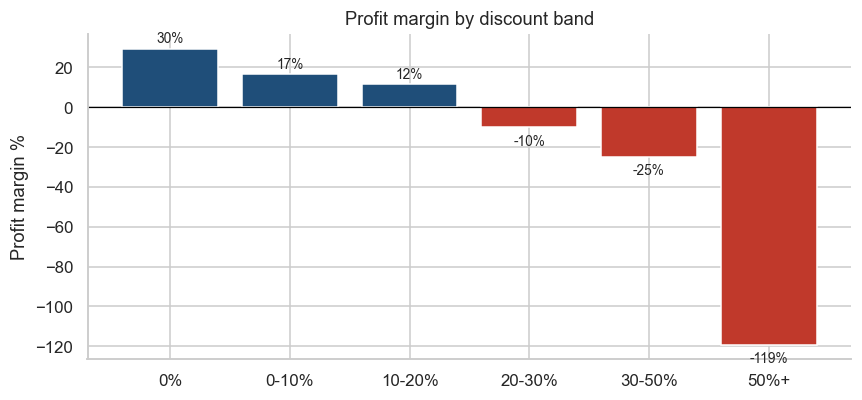

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(band.index.astype(str), band['Margin %'], color=[BLUE if v >= 0 else RED for v in band['Margin %']])
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Profit margin %'); ax.set_title('Profit margin by discount band')
for i, v in enumerate(band['Margin %']):
    ax.text(i, v + (3 if v >= 0 else -9), f'{v:.0f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig(IMG/'04_discount_vs_margin.png'); plt.show()

In [18]:
high = df[df['Discount'] > 0.20]
print(f"Lines with discount above 20%: {len(high):,} ({len(high)/len(df)*100:.1f}% of lines)")
print(f"Their total profit: {high['Profit'].sum():,.0f}  vs company total profit: {df['Profit'].sum():,.0f}")
print(f"Lines with discount of 20% or less: profit {df.loc[df['Discount']<=0.20,'Profit'].sum():,.0f}")

Lines with discount above 20%: 1,392 (13.9% of lines)
Their total profit: -135,364  vs company total profit: 286,409
Lines with discount of 20% or less: profit 421,773


## 9. Regions

In [19]:
reg = df.groupby('Region').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), AvgDiscount=('Discount','mean'))
reg['Margin %'] = reg['Profit'] / reg['Sales'] * 100
reg['AvgDiscount %'] = reg['AvgDiscount'] * 100
reg = reg.drop(columns='AvgDiscount').sort_values('Margin %')
reg

,Sales,Profit,Margin %,AvgDiscount %
Region,,,,
Central,"501,239.89","39,706.36",7.92,24.04
South,"391,721.91","46,749.43",11.93,14.73
East,"678,499.87","91,534.84",13.49,14.53
West,"725,457.82","108,418.45",14.94,10.93


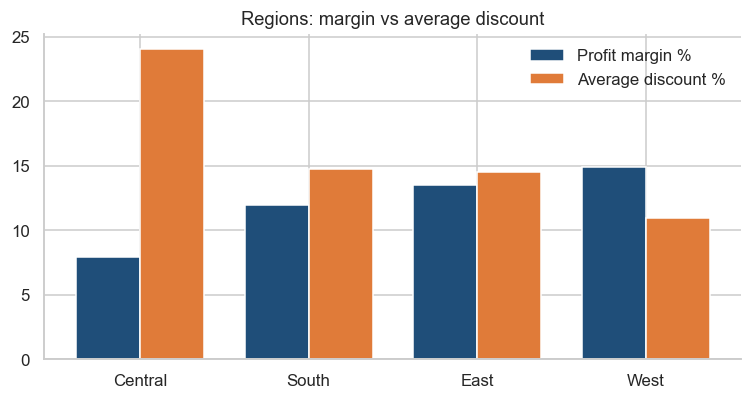

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(reg)); w = 0.38
ax.bar(x - w/2, reg['Margin %'], w, color=BLUE, label='Profit margin %')
ax.bar(x + w/2, reg['AvgDiscount %'], w, color=ORANGE, label='Average discount %')
ax.set_xticks(x); ax.set_xticklabels(reg.index); ax.legend(frameon=False)
ax.set_title('Regions: margin vs average discount')
plt.tight_layout(); plt.savefig(IMG/'05_region_margin_discount.png'); plt.show()

## 10. Top products and returns

In [21]:
top = df.groupby('Product Name').agg(Sales=('Sales','sum'), Profit=('Profit','sum')).nlargest(10, 'Sales')
top['Margin %'] = top['Profit'] / top['Sales'] * 100
top

,Sales,Profit,Margin %
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",40.91
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,"27,453.38","7,753.04",28.24
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",-8.00
HON 5400 Series Task Chairs for Big and Tall,"21,870.58",0.00,0.00
GBC DocuBind TL300 Electric Binding System,"19,823.48","2,233.51",11.27
GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50",760.98,4.00
Hewlett Packard LaserJet 3310 Copier,"18,839.69","6,983.88",37.07
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color","18,374.90","4,094.98",22.29
GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",-10.45


In [22]:
ret_orders = df.drop_duplicates('Order ID')['Returned'].eq('Yes').mean() * 100
ret_sales  = df.loc[df['Returned'] == 'Yes', 'Sales'].sum() / df['Sales'].sum() * 100
print(f'Returned orders: {ret_orders:.1f}% of orders | Returned sales value: {ret_sales:.1f}% of sales')
df.groupby('Category').apply(lambda g: g.loc[g['Returned']=='Yes','Sales'].sum()/g['Sales'].sum()*100, include_groups=False).round(1).rename('Returned sales % by category')

Returned orders: 5.9% of orders | Returned sales value: 7.9% of sales


Category
Furniture         8.00
Office Supplies   6.80
Technology        8.70
Name: Returned sales % by category, dtype: float64

## 11. Export

In [23]:
out_cols = ['Row ID','Order ID','Order Date','Ship Date','Ship Mode','Customer ID','Customer Name','Segment','Country','City','State',
            'Postal Code','Region','Regional Manager','Product ID','Category','Sub-Category','Product Name','Sales','Quantity','Discount','Profit',
            'Order Year','Order Month','Profit Margin','Discount Band','Ship Days','Returned']
clean = df[out_cols].copy()
clean['Discount Band'] = clean['Discount Band'].astype(str)
clean.to_csv(ROOT/'data/processed/orders_clean.csv', index=False, date_format='%Y-%m-%d')

summary = pd.DataFrame({'Metric': ['Rows','Orders','Total Sales','Total Profit','Profit Margin %'],
                        'Value':  [len(clean), clean['Order ID'].nunique(), round(clean['Sales'].sum(), 2), round(clean['Profit'].sum(), 2),
                                   round(clean['Profit'].sum()/clean['Sales'].sum()*100, 2)]})
summary.to_csv(ROOT/'data/processed/python_summary_totals.csv', index=False)
summary

,Metric,Value
0,Rows,"9,993.00"
1,Orders,"5,009.00"
2,Total Sales,"2,296,919.49"
3,Total Profit,"286,409.08"
4,Profit Margin %,12.47


## 12. Findings

1. **Growth:** sales rose from about $484K (2015) to $733K (2018); profit margin moved from 10.2% to 12.7%.
2. **Seasonality:** September, November and December bring about 43% of all sales; January and February are the weakest months.
3. **Discounts:** every discount band up to 20% is profitable, every band above 20% loses money. Lines discounted above 20% lost about $135K in total, against $286K total profit.
4. **Product mix:** Furniture is 32% of sales but only 6% of profit. Tables, Bookcases and Supplies lose money overall.
5. **Regions:** Central has the lowest margin (7.9%) and the highest average discount (24%); West has the highest margin (14.9%) and the lowest discount (11%).
6. **Returns:** about 6% of orders and 8% of sales value are returned.

*These are associations in one sample dataset. They show where to look, not proof of cause.*